In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
df = pd.read_csv("IPL_Moneyball_Merged_2008_2026.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully
Shape: (3311, 27)


,season,player,runs,balls_faced,innings,fours,sixes,dismissals,balls_bowled,runs_conceded,...,acquisition_type,base_price_lakh,final_price_lakh,bat_style,bowl_style,player_full_name,strike_rate,batting_avg,economy,bowling_avg
0,2008,A Chopra,42,52,5,5,0,5,0,0,...,NaN,NaN,NaN,Right hand Bat,"Right arm Medium, Right arm Offbreak",Aakash Chopra,80.77,8.40,NaN,NaN
1,2008,A Kumble,13,17,4,1,0,2,230,304,...,auction,NaN,125.0,Right hand Bat,Legbreak Googly,Anil Kumble,76.47,6.50,7.93,43.43
2,2008,A Mishra,37,42,3,3,0,3,119,138,...,NaN,NaN,NaN,Right hand Bat,Legbreak,Amit Mishra,88.10,12.33,6.96,12.55
3,2008,A Mukund,0,1,1,0,0,1,0,0,...,NaN,NaN,NaN,Left hand Bat,Legbreak Googly,Abhinav Mukund,0.00,0.00,NaN,NaN
4,2008,A Nehra,3,13,3,0,0,1,269,348,...,auction,NaN,100.0,Right hand Bat,Left arm Medium fast,Ashish Nehra,23.08,3.00,7.76,29.00


In [5]:
cleaned_df = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", cleaned_df.shape)

Original dataset: (3311, 27)
Working dataset: (3311, 27)


In [6]:
missing_count = cleaned_df.isnull().sum()

missing_percentage = (
    cleaned_df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_report)

                  Missing Values  Missing Percentage
base_price_lakh             3109           93.899124
role                        2418           73.029296
nationality                 2296           69.344609
bowling_avg                 1520           45.907581
final_price_lakh            1480           44.699487
status                      1200           36.242827
team                        1200           36.242827
auction_name                1200           36.242827
acquisition_type            1200           36.242827
economy                     1130           34.128662
batting_avg                  677           20.446995
strike_rate                  383           11.567502
bowl_style                    26            0.785261


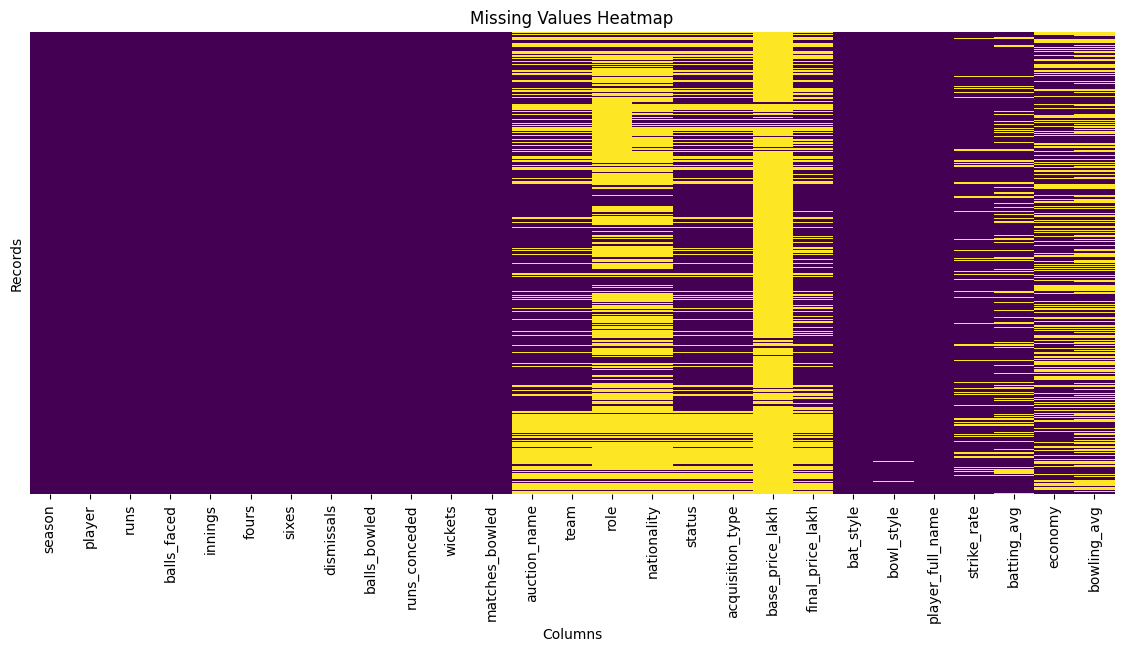

In [7]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    cleaned_df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.show()

In [8]:
categorical_cols = cleaned_df.select_dtypes(
    include="object"
).columns

print(cleaned_df[categorical_cols].isnull().sum())

player                 0
auction_name        1200
team                1200
role                2418
nationality         2296
status              1200
acquisition_type    1200
bat_style              0
bowl_style            26
player_full_name       0
dtype: int64


In [9]:
cleaned_df["bat_style"] = cleaned_df["bat_style"].fillna("Unknown")

print("Missing bat_style values:",
      cleaned_df["bat_style"].isnull().sum())

Missing bat_style values: 0


In [10]:
numeric_cols = cleaned_df.select_dtypes(
    include=np.number
).columns

print(cleaned_df[numeric_cols].isnull().sum())

season                 0
runs                   0
balls_faced            0
innings                0
fours                  0
sixes                  0
dismissals             0
balls_bowled           0
runs_conceded          0
wickets                0
matches_bowled         0
base_price_lakh     3109
final_price_lakh    1480
strike_rate          383
batting_avg          677
economy             1130
bowling_avg         1520
dtype: int64


In [12]:
numeric_missing = cleaned_df[numeric_cols].isnull().sum()

numeric_missing = numeric_missing[numeric_missing > 0]

print("Numeric columns with missing values:")
print(numeric_missing)

Numeric columns with missing values:
base_price_lakh     3109
final_price_lakh    1480
strike_rate          383
batting_avg          677
economy             1130
bowling_avg         1520
dtype: int64


In [13]:
print("Remaining missing values in each column:")
print(cleaned_df.isnull().sum())

print("\nTotal missing values:")
print(cleaned_df.isnull().sum().sum())

Remaining missing values in each column:
season                 0
player                 0
runs                   0
balls_faced            0
innings                0
fours                  0
sixes                  0
dismissals             0
balls_bowled           0
runs_conceded          0
wickets                0
matches_bowled         0
auction_name        1200
team                1200
role                2418
nationality         2296
status              1200
acquisition_type    1200
base_price_lakh     3109
final_price_lakh    1480
bat_style              0
bowl_style            26
player_full_name       0
strike_rate          383
batting_avg          677
economy             1130
bowling_avg         1520
dtype: int64

Total missing values:
17839


In [14]:
print("Total duplicate records:", cleaned_df.duplicated().sum())

Total duplicate records: 0


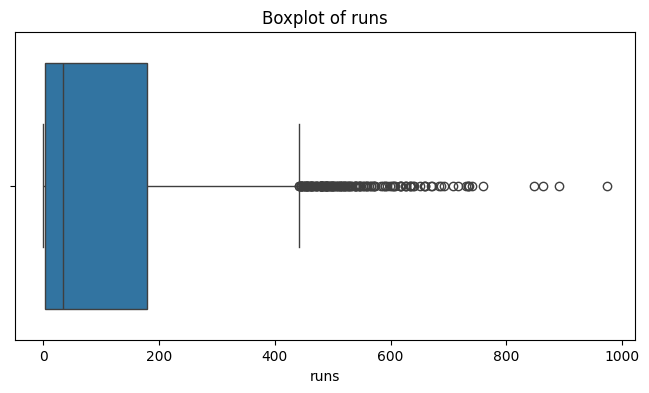

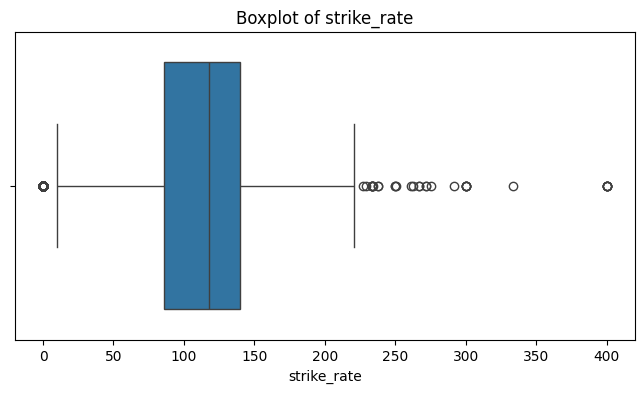

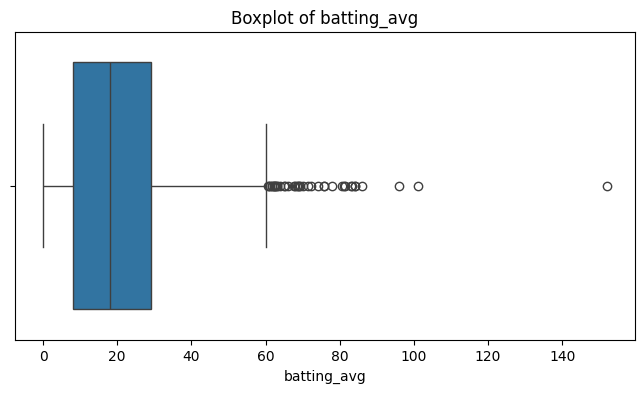

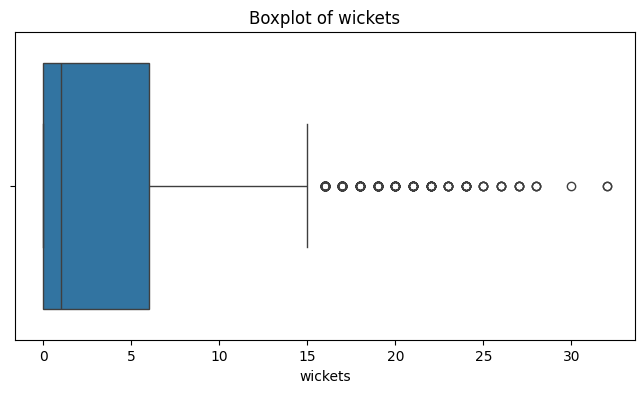

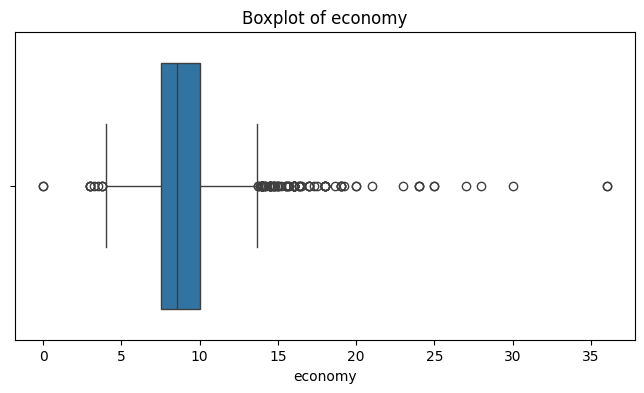

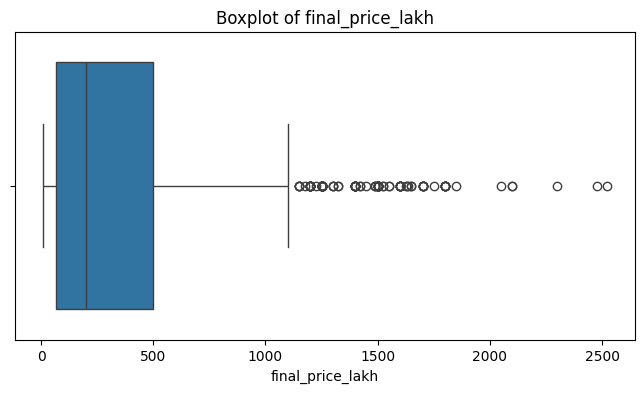

In [15]:
outlier_columns = [
    "runs",
    "strike_rate",
    "batting_avg",
    "wickets",
    "economy",
    "final_price_lakh"
]

for col in outlier_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=cleaned_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [16]:
for col in outlier_columns:

    Q1 = cleaned_df[col].quantile(0.25)
    Q3 = cleaned_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = cleaned_df[
        (cleaned_df[col] < lower_limit) |
        (cleaned_df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outlier Count:", len(outliers))


Column: runs
Lower Limit: -258.5
Upper Limit: 441.5
Outlier Count: 156

Column: strike_rate
Lower Limit: 4.2749999999999915
Upper Limit: 221.435
Outlier Count: 182

Column: batting_avg
Lower Limit: -23.5
Upper Limit: 60.5
Outlier Count: 39

Column: wickets
Lower Limit: -9.0
Upper Limit: 15.0
Outlier Count: 203

Column: economy
Lower Limit: 3.8250000000000006
Upper Limit: 13.705
Outlier Count: 107

Column: final_price_lakh
Lower Limit: -578.125
Upper Limit: 1146.875
Outlier Count: 130


In [17]:
zscore_columns = [
    "runs",
    "strike_rate",
    "batting_avg",
    "wickets",
    "economy"
]

for col in zscore_columns:

    values = cleaned_df[col].dropna()

    z_scores = stats.zscore(values)

    outliers = values[np.abs(z_scores) > 3]

    print("\nColumn:", col)
    print("Z-score Outliers:", len(outliers))


Column: runs
Z-score Outliers: 46

Column: strike_rate
Z-score Outliers: 20

Column: batting_avg
Z-score Outliers: 25

Column: wickets
Z-score Outliers: 44

Column: economy
Z-score Outliers: 31


In [18]:
comparison = pd.DataFrame({
    "Column": [
        "runs",
        "strike_rate",
        "batting_avg",
        "wickets",
        "economy"
    ],
    "IQR Outliers": [156, 182, 39, 203, 107],
    "Z-score Outliers": [46, 20, 25, 44, 31]
})

print(comparison)

        Column  IQR Outliers  Z-score Outliers
0         runs           156                46
1  strike_rate           182                20
2  batting_avg            39                25
3      wickets           203                44
4      economy           107                31


In [19]:
comparison_df = pd.DataFrame({
    "Dataset": ["Original", "Working Copy"],
    "Rows": [df.shape[0], cleaned_df.shape[0]],
    "Columns": [df.shape[1], cleaned_df.shape[1]],
    "Missing Values": [
        df.isnull().sum().sum(),
        cleaned_df.isnull().sum().sum()
    ],
    "Duplicates": [
        df.duplicated().sum(),
        cleaned_df.duplicated().sum()
    ]
})

print(comparison_df)

        Dataset  Rows  Columns  Missing Values  Duplicates
0      Original  3311       27           17839           0
1  Working Copy  3311       27           17839           0


In [20]:
print("WEEK 03 - FINAL DATA QUALITY SUMMARY")

print("Original Shape:", df.shape)
print("Working Copy Shape:", cleaned_df.shape)

print("Original Missing Values:",
      df.isnull().sum().sum())

print("Remaining Missing Values:",
      cleaned_df.isnull().sum().sum())

print("Duplicate Records:",
      cleaned_df.duplicated().sum())

print("\nCleaning and Outlier Analysis Completed")

WEEK 03 - FINAL DATA QUALITY SUMMARY
Original Shape: (3311, 27)
Working Copy Shape: (3311, 27)
Original Missing Values: 17839
Remaining Missing Values: 17839
Duplicate Records: 0

Cleaning and Outlier Analysis Completed


In [21]:
cleaned_df.to_csv(
    "IPL_Moneyball_Cleaned_Week03.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!
